<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1026/mobile_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 구글 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

sns.set_theme(style="whitegrid")

# 1. 데이터 구조 확인

In [4]:
# 데이터 불러오기
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")

print("데이터 크기:", df.shape)

print("\n처음 5개 데이터")
display(df.head())

print("\n변수 이름")
print(df.columns.tolist())

print("\n자료형")
print(df.dtypes)

print("\n데이터 정보")
df.info()

데이터 크기: (2000, 21)

처음 5개 데이터


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1



변수 이름
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']

자료형
battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_

# 2. 결측치와 중복 데이터 확인

In [5]:
print("변수별 결측치 개수")
print(df.isnull().sum())

print("\n전체 결측치 개수:", df.isnull().sum().sum())

print("\n중복 행 개수")
print(df.duplicated().sum())

변수별 결측치 개수
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

전체 결측치 개수: 0

중복 행 개수
0


**확인 결과**: 모든 변수의 결측치가 0개이고, 중복 행도 0개 → 결측치 처리 / 중복 제거 필요 없음

# 3. 분석 변수 지정

In [6]:
target_col = "battery_power"

# price_range는 예측 입력 변수에서 제외하고 분석
feature_cols = [
    col for col in df.columns
    if col not in [target_col, "price_range"]
]

print("예측 대상:", target_col)
print("입력 변수 후보:", feature_cols)
print("입력 변수 개수:", len(feature_cols))

예측 대상: battery_power
입력 변수 후보: ['blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi']
입력 변수 개수: 19


# 4. 값(레이블) 개수 확인



In [7]:
print("타깃 고유값 개수:", len(df[target_col].unique()))
print("타깃 최솟값 / 최댓값:", df[target_col].min(), "/", df[target_col].max())

print("\n타깃 값별 개수 (상위 10개)")
print(df[target_col].value_counts().head(10))

타깃 고유값 개수: 1094
타깃 최솟값 / 최댓값: 501 / 1998

타깃 값별 개수 (상위 10개)
battery_power
1589    6
1872    6
618     6
772     5
1063    5
1083    5
832     5
504     5
1414    5
1310    5
Name: count, dtype: int64


In [8]:
cat_cols = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi", "price_range"]

for col in cat_cols:
    print(f"\n[{col}]")
    print(df[col].value_counts())


[blue]
blue
0    1010
1     990
Name: count, dtype: int64

[dual_sim]
dual_sim
1    1019
0     981
Name: count, dtype: int64

[four_g]
four_g
1    1043
0     957
Name: count, dtype: int64

[three_g]
three_g
1    1523
0     477
Name: count, dtype: int64

[touch_screen]
touch_screen
1    1006
0     994
Name: count, dtype: int64

[wifi]
wifi
1    1014
0     986
Name: count, dtype: int64

[price_range]
price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64


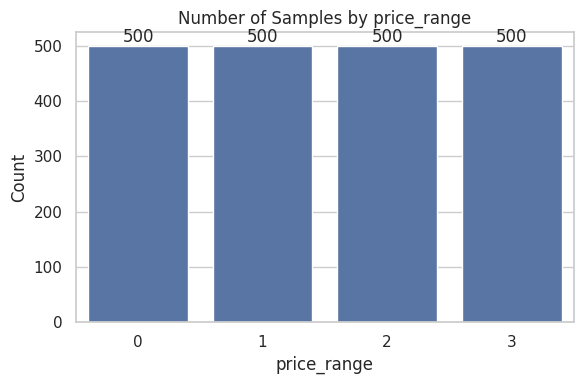

In [31]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=df,
    x="price_range"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Samples by price_range")
plt.xlabel("price_range")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

**확인 결과**
- battery_power는 501 ~ 1998 사이에 고유값이 약 1,094개로, 특정 값에 몰리지 않고 고르게 퍼져 있음
- 0/1 범주형 변수(three_g 제외)는 두 값이 거의 반반으로 균형 잡혀 있고, three_g는 1이 약 76%로 한쪽이 더 많음
- price_range는 0~3 각각 500개씩 완전히 균형 → 비어있는 클래스 없음

# 5. 타깃 변수 기술통계량과 분포

In [10]:
display(df[[target_col]].describe().round(3))

,battery_power
count,2000.000
mean,1238.518
std,439.418
min,501.000
25%,851.750
50%,1226.000
75%,1615.250
max,1998.000


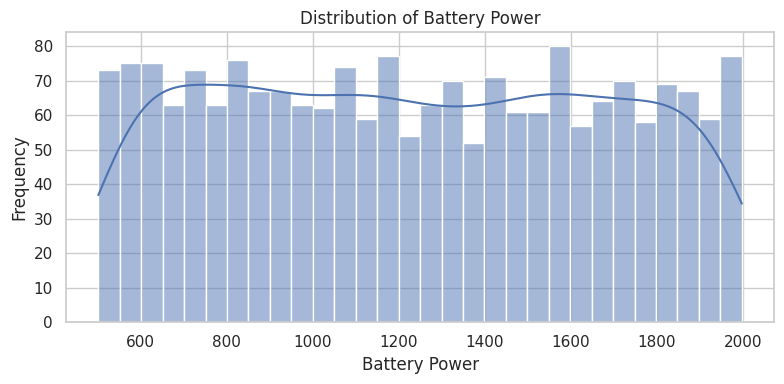

In [11]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x=target_col, bins=30, kde=True)

plt.title("Distribution of Battery Power")
plt.xlabel("Battery Power")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

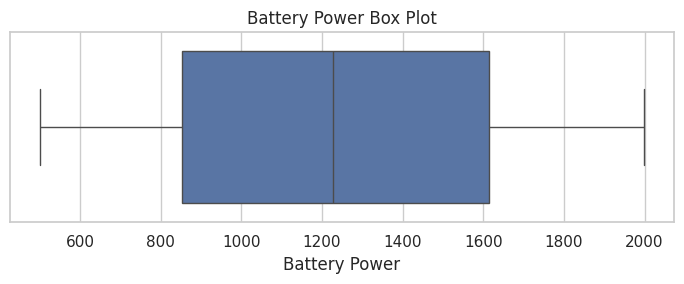

In [12]:
plt.figure(figsize=(7, 3))

sns.boxplot(data=df, x=target_col)

plt.title("Battery Power Box Plot")
plt.xlabel("Battery Power")

plt.tight_layout()
plt.show()

**확인 결과**: 평균 약 1239, 표준편차 약 439. 히스토그램이 봉우리 없이 평평한 형태(균등분포에 가까움)이고 이상치가 없음

# 6. 입력 변수와 battery_power의 상관관계

In [14]:
target_corr = (
    df[feature_cols + [target_col]]
    .corr()[target_col]
    .drop(target_col)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("battery_power와 상관관계가 높은 변수 순서")
display(target_corr.to_frame("Correlation").round(3))

print("price_range와 battery_power의 상관계수:", round(df["price_range"].corr(df[target_col]), 3))

battery_power와 상관관계가 높은 변수 순서


,Correlation
talk_time,0.053
dual_sim,-0.042
m_dep,0.034
fc,0.033
pc,0.031
sc_h,-0.030
n_cores,-0.030
sc_w,-0.021
four_g,0.016
px_height,0.015


price_range와 battery_power의 상관계수: 0.201


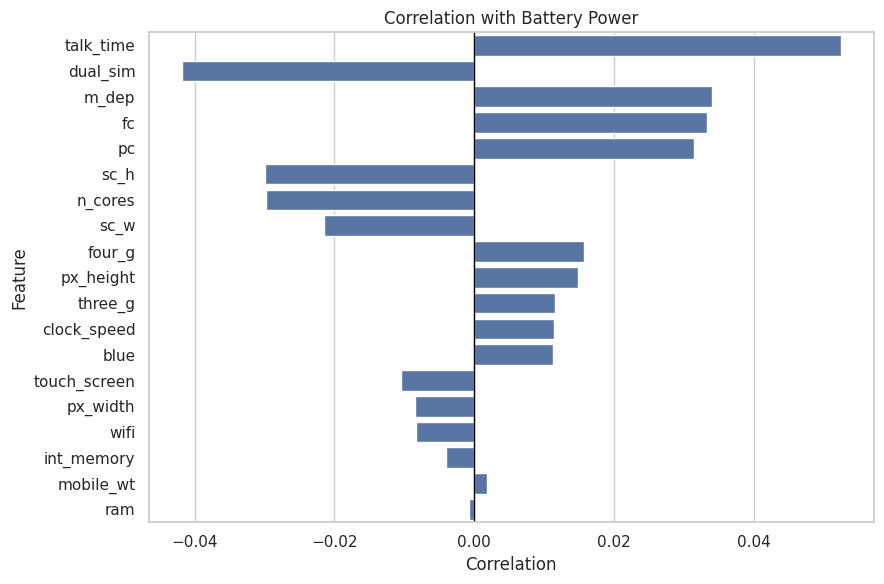

In [15]:
plt.figure(figsize=(9, 6))

sns.barplot(x=target_corr.values, y=target_corr.index)

plt.axvline(0, color="black", linewidth=1)
plt.title("Correlation with Battery Power")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**확인 결과**
- 가장 높은 talk_time도 상관계수가 약 0.05로, **모든 입력 변수의 |r|이 0.06 미만**
- 상관계수가 0에 가까우면 두 변수 사이에 선형 관계가 거의 없다는 의미
- 입력 변수에서 제외한 price_range만 약 0.20으로 약한 상관관계를 보임
- → 입력 변수만으로 battery_power를 예측하기는 어려울 것으로 예상됨

# 7. 상위 6개 변수와 battery_power의 산점도

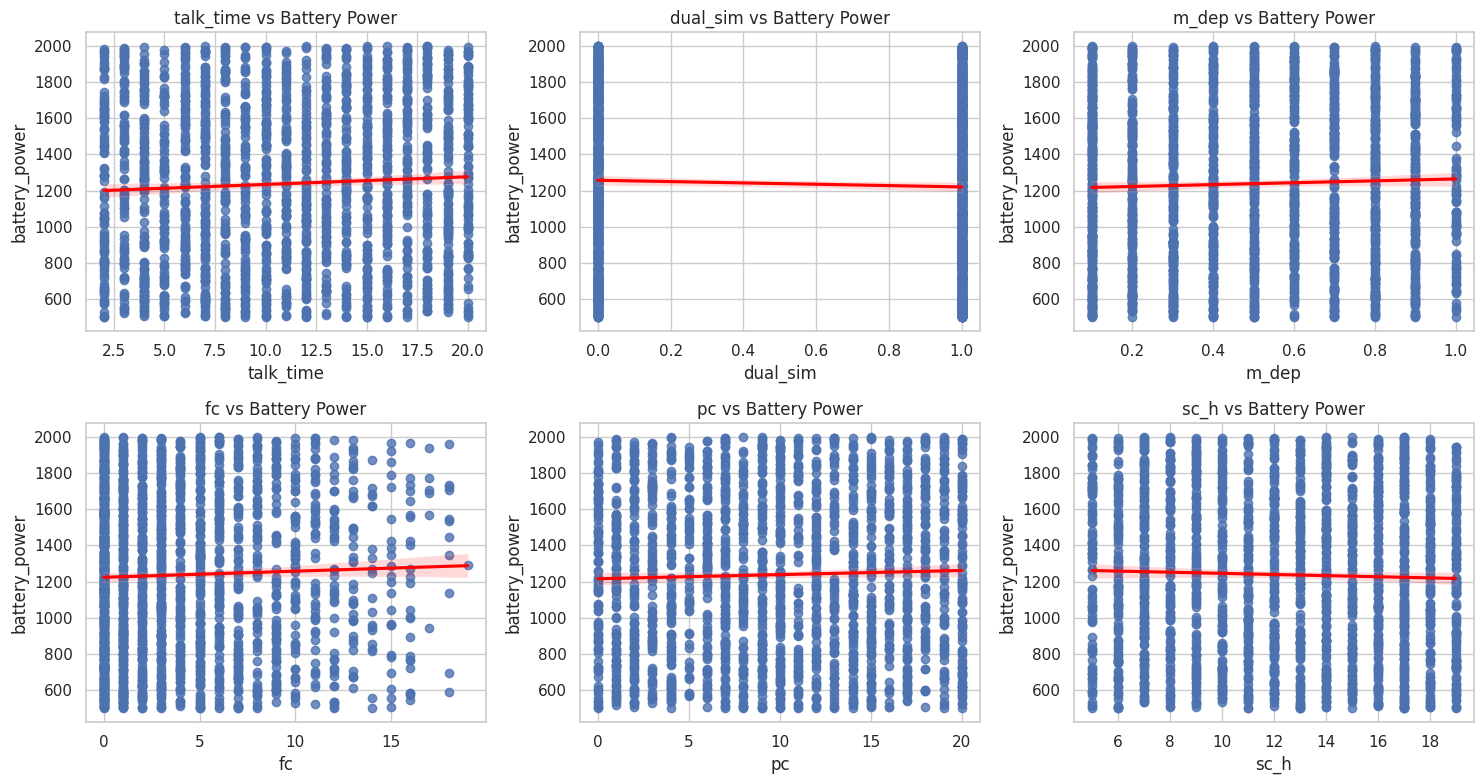

In [17]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.flatten()

for i, col in enumerate(top_cols):
    sns.regplot(data=df, x=col, y=target_col, ax=axs[i],
                line_kws=dict(color="red"))
    axs[i].set_title(f"{col} vs Battery Power")

plt.tight_layout()
plt.show()

**확인 결과**: 점들이 전체에 고르게 흩어져 있고 회귀선이 거의 수평 → 입력 변수가 바뀌어도 battery_power가 변하지 않음

**확인 결과**: 상관관계가 강한 조합
- fc <-> pc (약 0.64): 전면 카메라와 후면 카메라 화소
- three_g <-> four_g (약 0.58)
- px_height <-> px_width (약 0.51), sc_h <-> sc_w (약 0.51): 화면 크기/해상도의 가로·세로

입력 변수끼리는 관계가 있지만, battery_power와 관련된 변수는 없음

# 8. 모델 학습용 데이터 준비
- 입력: 상관관계 상위 6개 변수 (`top_cols`)
- 타깃: battery_power
- 8:2로 분할 후 StandardScaler로 표준화 (train 기준으로 fit)

In [20]:
X = df[top_cols].values.astype(np.float32)
y = df[target_col].values.astype(np.float32)

print("입력 변수:", top_cols)
print("X shape:", X.shape)
print("y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)

입력 변수: ['talk_time', 'dual_sim', 'm_dep', 'fc', 'pc', 'sc_h']
X shape: (2000, 6)
y shape: (2000,)

Train: (1600, 6)  Test: (400, 6)


# 9. 평가 지표 (Metric) 정의

| 지표 | 의미 |
|---|---|
| MSE (평균제곱오차) | 오차 제곱의 평균, 작을수록 좋음 |
| Accuracy (±10%) | 예측값이 실제값의 ±10% 안에 들어온 비율. 회귀는 정답이 연속값이라 정확히 맞히는 경우가 거의 없으므로, 허용오차 안에 들어오면 정답으로 계산 |

MSE는 EX_0914 샘플의 `mse_np` 함수처럼 NumPy로도 계산할 수 있고, Accuracy도 같은 방식으로 함수를 만든다.

In [21]:
def mse_np(actual, predicted):
    return np.mean((np.array(actual) - np.array(predicted)) ** 2)

def accuracy_np(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.mean(np.abs(actual - predicted) <= actual * 0.1)

results = {}
acc_results = {}

# 10. 기준선 (Baseline): 평균값으로만 예측
입력을 전혀 보지 않고 train 데이터의 평균값만 출력하는 경우. 학습한 모델은 최소한 이것보다 MSE가 낮아야 의미가 있다.

In [22]:
baseline_preds = [y_train.mean()] * len(y_test)

mse = mean_squared_error(y_test, baseline_preds)
acc = accuracy_np(y_test, baseline_preds)

results["Baseline (Mean)"] = mse
acc_results["Baseline (Mean)"] = acc

print('평균값 예측 평균제곱오차', mse)
print('평균값 예측 Accuracy', acc)

평균값 예측 평균제곱오차 188508.359375
평균값 예측 Accuracy 0.16


# 11. 기본 회귀 모델 4개 비교

In [23]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(kernel="linear")
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mse = mean_squared_error(y_test, preds)
    acc = accuracy_np(y_test, preds)

    results[name] = mse
    acc_results[name] = acc

    print(f"{name} MSE: {mse:.4f}, Accuracy: {acc:.4f}")

Linear Regression MSE: 188035.5625, Accuracy: 0.1475
Decision Tree MSE: 370949.7200, Accuracy: 0.1575
Random Forest MSE: 203907.7372, Accuracy: 0.1550
SVR MSE: 187641.2402, Accuracy: 0.1450


# 12. 인공신경망 회귀 모델

In [24]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [25]:
class RegressionModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RegressionModel(X_train.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [26]:
epochs = 100
loss_history = []

model.train()
for epoch in range(epochs):
    total_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        output = model(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    loss_history.append(total_loss / len(train_loader))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss / len(train_loader):.4f}")

Epoch [10/100], Loss: 374754.4644
Epoch [20/100], Loss: 209266.3612
Epoch [30/100], Loss: 202348.3934
Epoch [40/100], Loss: 198799.3525
Epoch [50/100], Loss: 196845.7700
Epoch [60/100], Loss: 194909.3692
Epoch [70/100], Loss: 193618.6766
Epoch [80/100], Loss: 192642.7878
Epoch [90/100], Loss: 191905.5498
Epoch [100/100], Loss: 190972.3234


In [27]:
model.eval()
preds, actuals = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch).cpu().numpy().flatten()
        preds.extend(outputs)
        actuals.extend(y_batch.numpy().flatten())

nn_mse = mean_squared_error(actuals, preds)
nn_acc = accuracy_np(actuals, preds)

results["Neural Network"] = nn_mse
acc_results["Neural Network"] = nn_acc

print(f"Neural Network Test MSE: {nn_mse:.4f}")
print(f"Neural Network Test Accuracy: {nn_acc:.4f}")

Neural Network Test MSE: 193707.4480
Neural Network Test Accuracy: 0.1675


# 13. 학습 Loss 변화
**학습 Loss란?**
- 모델이 train 데이터를 얼마나 틀리게 예측했는지 나타내는 값
- 1 epoch(train 데이터 전체를 한 번 학습)마다 Loss의 평균을 `loss_history`에 저장

**Loss 변화의 의미**
- Loss가 줄어든다 → 모델이 학습하면서 예측이 점점 정답에 가까워지고 있음
- Loss가 더 이상 줄지 않고 평평해진다 → 모델이 더 배울 것이 없는 상태

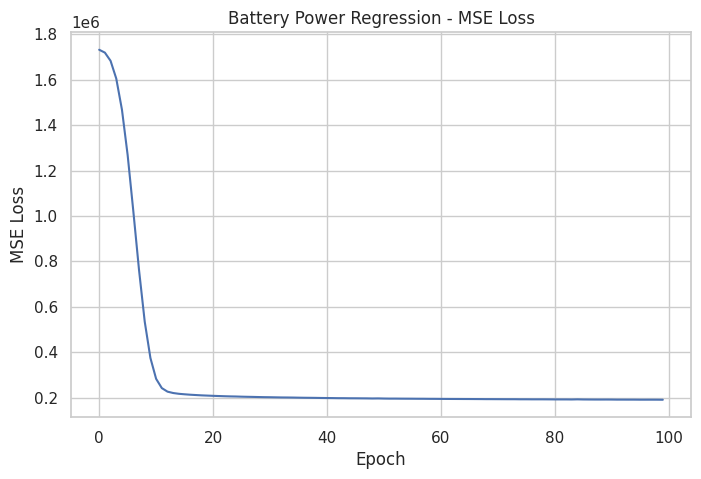

마지막 epoch Train Loss: 190972.32
train 타깃의 분산 (평균으로 예측할 때의 MSE): 194119.23


In [28]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Battery Power Regression - MSE Loss")
plt.xlabel("Epoch") # 학습 반복 횟수
plt.ylabel("MSE Loss")  # 작을수록 예측이 정답에 가까움
plt.grid(True)
plt.show()

print("마지막 epoch Train Loss:", round(loss_history[-1], 2))
print("train 타깃의 분산 (평균으로 예측할 때의 MSE):", round(y_train.var(), 2))

**확인 결과**
- 처음 약 20 epoch 동안 Loss가 크게 줄어듦
  - 처음에는 모델이 0에 가까운 값을 예측하다가, battery_power의 평균(약 1239) 근처 값을 예측하도록 바뀌는 과정
- 이후에는 Loss가 약 19만 근처에서 거의 줄지 않고 평평해짐
- 이 값은 평균값으로만 예측했을 때의 MSE(Baseline, 약 18~19만)와 비슷함
- → 학습 자체는 정상적으로 진행됐지만, 입력 변수에서 battery_power를 예측할 정보를 찾지 못해 "평균값으로 예측"하는 수준에서 학습이 멈춤

# 14. 실제값 vs 예측값

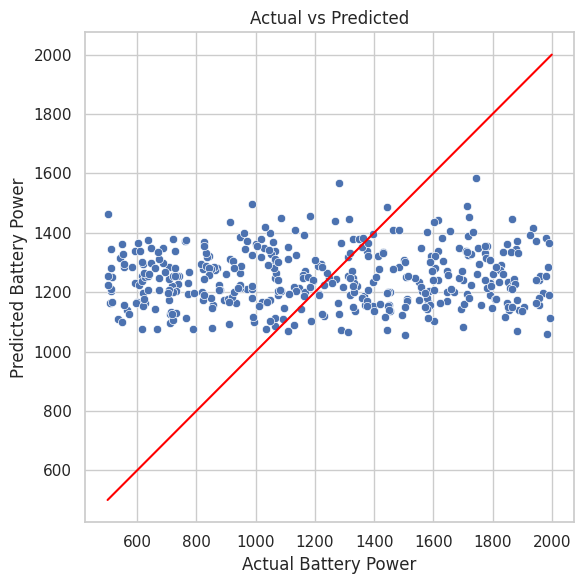

실제값 범위: 502.0 ~ 1993.0
예측값 범위: 1055.11 ~ 1583.18


In [29]:
plt.figure(figsize=(6, 6))

sns.scatterplot(x=actuals, y=preds)
plt.plot([500, 2000], [500, 2000], color="red")

plt.title("Actual vs Predicted")
plt.xlabel("Actual Battery Power")
plt.ylabel("Predicted Battery Power")

plt.tight_layout()
plt.show()

print("실제값 범위:", min(actuals), "~", max(actuals))
print("예측값 범위:", round(min(preds), 2), "~", round(max(preds), 2))

# 15. 전체 모델 성능 비교

In [30]:
print("===== 모델별 MSE / Accuracy 비교 (MSE 낮은 순) =====")

for name, mse in sorted(results.items(), key=lambda x: x[1]):
    print(f"{name}: MSE {mse:.4f}, Accuracy {acc_results[name]:.4f}")

best_model = min(results, key=results.get)

print("\nMSE 기준 최적 모델:", best_model)
print(f"최저 MSE: {results[best_model]:.4f}")

===== 모델별 MSE / Accuracy 비교 (MSE 낮은 순) =====
SVR: MSE 187641.2402, Accuracy 0.1450
Linear Regression: MSE 188035.5625, Accuracy 0.1475
Baseline (Mean): MSE 188508.3594, Accuracy 0.1600
Neural Network: MSE 193707.4480, Accuracy 0.1675
Random Forest: MSE 203907.7372, Accuracy 0.1550
Decision Tree: MSE 370949.7200, Accuracy 0.1575

MSE 기준 최적 모델: SVR
최저 MSE: 187641.2402


# 16. 결과 분석

### (1) 결과 요약

- MSE가 가장 낮은 모델은 SVR
- 하지만 평균값으로만 예측한 Baseline과 MSE가 거의 같음
- Accuracy는 모든 모델이 약 15% 정도로 매우 낮음

### (2) 그래프 확인
- Loss 그래프: 처음에는 크게 줄지만, 어느 정도 이후로는 더 이상 줄지 않음
- 실제값 vs 예측값 그래프: 점들이 빨간 대각선을 따르지 않고 가운데(평균 근처)에 몰려 있음
- → 모델이 입력값과 상관없이 평균에 가까운 값만 예측하고 있음

### (3) 성능이 낮은 이유
1. 입력 변수와 battery_power의 상관관계가 거의 없음 (모든 변수가 0.06 미만)
2. 산점도에서도 회귀선이 거의 수평이라, 입력 값이 바뀌어도 battery_power가 변하지 않음
3. 모델을 바꿔도 결과가 모두 비슷함 → 모델의 문제가 아니라 데이터의 문제

### (4) 결론
이 데이터의 입력 변수로는 battery_power를 예측하기 어렵다.
성능을 높이려면 배터리 용량과 관련 있는 변수가 더 필요하다.